### Practice Questions

1. Explore the effect of k further: try k values [1, 2, 3, 4, 5, ...] (both even and odd) on binary classification data and count how often ties occur with even k (check how Counter.most_common() handles ties).
2. Implement Manhattan distance and compare: besides Euclidean distance, another common metric is Manhattan distance:
   manhattan_distance = |x1-x2| + |y1-y2| + ...   (no squares or square root, just the sum of absolute differences)

`Add a new manhattan_distance method to your KNNClassifierScratch and compare the results of both distance metrics. Does the accuracy change?`

3. Test again without scaling: try the same k values without StandardScaler. How much does accuracy drop? Confirm that a large-scale feature such as income dominates the distance in practice.
4. Implement the Elbow Method: loop k from 1 to 30 and plot test accuracy (k on the x-axis, accuracy on the y-axis). Find the elbow point where improvement plateaus (the same technique used for max_depth in the Decision Tree).

### 🏗️ Mini Project — KNN

"Loan Default Risk Classifier"

In [111]:
import numpy as np
from collections import Counter
from matplotlib import pyplot as plt

In [112]:
import numpy as np

np.random.seed(15)
n_samples = 300

annual_income = np.random.normal(50000, 20000, n_samples).clip(10000, 150000)
credit_score = np.random.normal(650, 100, n_samples).clip(300, 850)
loan_amount = np.random.normal(20000, 10000, n_samples).clip(1000, 60000)
existing_debts = np.random.poisson(2, n_samples)

# True relationship: high income + high credit score + low loan/debt = low default risk
risk_score = (
    -0.00003 * annual_income 
    - 0.008 * credit_score 
    + 0.00005 * loan_amount 
    + 0.3 * existing_debts
    + 5
)
default_prob = 1 / (1 + np.exp(-risk_score))
will_default = np.random.binomial(1, default_prob)

X = np.column_stack([annual_income, credit_score, loan_amount, existing_debts])
y = will_default

print(f"Default rate: {y.mean():.1%}")

Default rate: 51.0%


In [113]:
# Using Eucliden Distance

class KNNClassifierScratch:
    def __init__(self, k=3):
        self.k = k
        self.X_train = None
        self.y_train = None
    
    def fit(self, X, y):
        # Remember: in KNN, "fit" only STORES the data; nothing is trained
        self.X_train = X
        self.y_train = y
    
    def euclidean_distance(self, point1, point2):
        return np.sqrt(np.sum((point1 - point2) ** 2))
    
    def predict_single(self, x):
        distances = [self.euclidean_distance(x, x_train) for x_train in self.X_train]  
        
        k_indices = np.argsort(distances)[:self.k] 
        
        k_nearest_labels = [self.y_train[i] for i in k_indices] 

        most_common = Counter(k_nearest_labels).most_common(1)[0][0] 
        
        return most_common
    
    def predict(self, X):
        return np.array([self.predict_single(x) for x in X])

In [114]:
# Using Manhttan Distance

class KNNClassifierManhattan:
    def __init__(self, k=3):
        self.k = k
        self.X_train = None
        self.y_train = None
    
    def fit(self, X, y):
        # Remember: in KNN, "fit" only STORES the data; nothing is trained
        self.X_train = X
        self.y_train = y
    
    def manhattan_distance(self, point1, point2):
        return np.sum(np.abs(point1 - point2))  
    
    def predict_single(self, x):
        distances = [self.manhattan_distance(x, x_train) for x_train in self.X_train]  
        
        k_indices = np.argsort(distances)[:self.k] 
        
        k_nearest_labels = [self.y_train[i] for i in k_indices] 

        most_common = Counter(k_nearest_labels).most_common(1)[0][0] 
        
        return most_common
    
    def predict(self, X):
        return np.array([self.predict_single(x) for x in X])

#### WITHOUT SCALING

In [115]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)

🎯 Sweet Spot K = 11 (Max Accuracy = 66.67%)


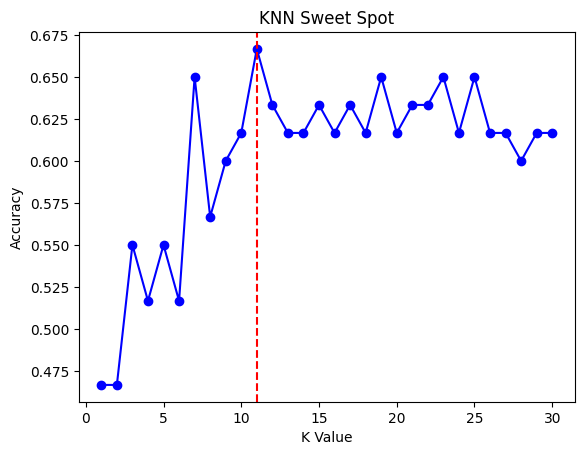

In [116]:
# Using Euidelian Distance
k_accuracies = []
k_values = list(range(1, 31))

for k in range(1,31):
    k_edu = KNNClassifierScratch(k=k)
    k_edu.fit(X_train, y_train)
    pred = k_edu.predict(X_test)
    accuracy = np.mean(pred == y_test)

    k_accuracies.append(accuracy)


best_k = k_values[np.argmax(k_accuracies)]
print(f"🎯 Sweet Spot K = {best_k} (Max Accuracy = {max(k_accuracies):.2%})")

# 3. Simple Plot
plt.plot(k_values, k_accuracies, marker='o', color='blue')
plt.axvline(x=best_k, color='red', linestyle='--') # Draws a simple red line on the best K
plt.title('KNN Sweet Spot')
plt.xlabel('K Value')
plt.ylabel('Accuracy')
plt.show()

🎯 Sweet Spot K = 9 (Max Accuracy = 65.00%)


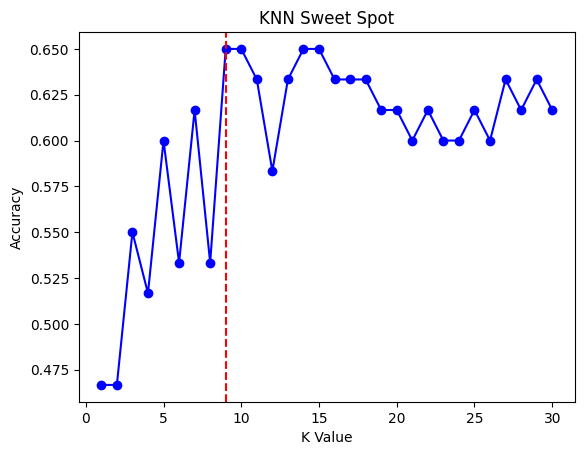

In [117]:
# Using Manhattan Distance

k_accuracies_m = []
k_values = list(range(1, 31))

for k in range(1,31):
    k_edu = KNNClassifierManhattan(k=k)
    k_edu.fit(X_train, y_train)
    pred = k_edu.predict(X_test)
    accuracy = np.mean(pred == y_test)

    k_accuracies_m.append(accuracy)

best_k = k_values[np.argmax(k_accuracies_m)]
print(f"🎯 Sweet Spot K = {best_k} (Max Accuracy = {max(k_accuracies_m):.2%})")

# 3. Simple Plot
plt.plot(k_values, k_accuracies_m, marker='o', color='blue')
plt.axvline(x=best_k, color='red', linestyle='--') # Draws a simple red line on the best K
plt.title('KNN Sweet Spot')
plt.xlabel('K Value')
plt.ylabel('Accuracy')
plt.show()

🎯 Sweet Spot K = 11 (Max Accuracy = 66.67%)


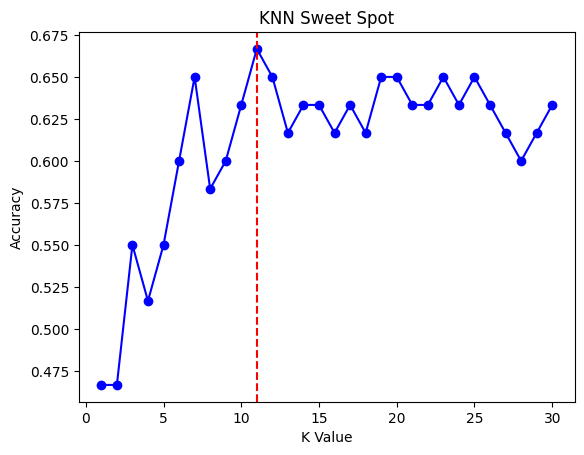

In [118]:
# Using Sklearn

from sklearn.neighbors import KNeighborsClassifier

model_results = []
k_values = list(range(1, 31))

for k in range(1,31):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)

    prediction = model.predict(X_test)
    probability = model.predict_proba(X_test)

    model_accuracy = model.score(X_test, y_test)

    model_results.append(model_accuracy)

best_k = k_values[np.argmax(model_results)]
print(f"🎯 Sweet Spot K = {best_k} (Max Accuracy = {max(model_results):.2%})")

# 3. Simple Plot
plt.plot(k_values, model_results, marker='o', color='blue')
plt.axvline(x=best_k, color='red', linestyle='--')
plt.title('KNN Sweet Spot')
plt.xlabel('K Value')
plt.ylabel('Accuracy')
plt.show()

🎯 Sweet Spot K = 16 (Max Accuracy = 66.67%)


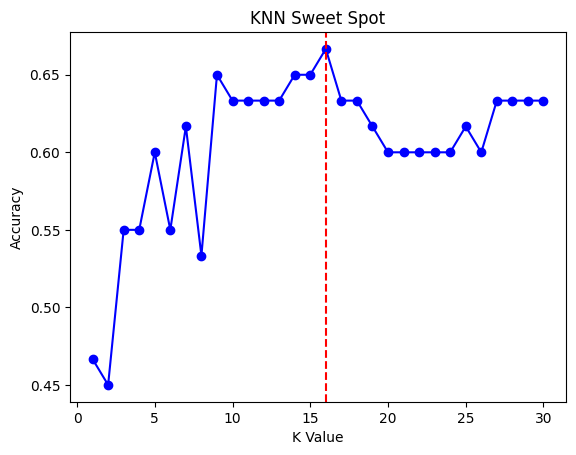

In [125]:
# Using Sklearn

from sklearn.neighbors import KNeighborsClassifier

model_results = []
k_values = list(range(1, 31))

for k in range(1,31):
    model = KNeighborsClassifier(n_neighbors=k, metric= 'manhattan')
    model.fit(X_train, y_train)

    prediction = model.predict(X_test)
    probability = model.predict_proba(X_test)

    model_accuracy = model.score(X_test, y_test)

    model_results.append(model_accuracy)

best_k = k_values[np.argmax(model_results)]
print(f"🎯 Sweet Spot K = {best_k} (Max Accuracy = {max(model_results):.2%})")

# 3. Simple Plot
plt.plot(k_values, model_results, marker='o', color='blue')
plt.axvline(x=best_k, color='red', linestyle='--')
plt.title('KNN Sweet Spot')
plt.xlabel('K Value')
plt.ylabel('Accuracy')
plt.show()

#### WITH SCALING

In [119]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

🎯 Sweet Spot K = 9 (Max Accuracy = 75.00%)


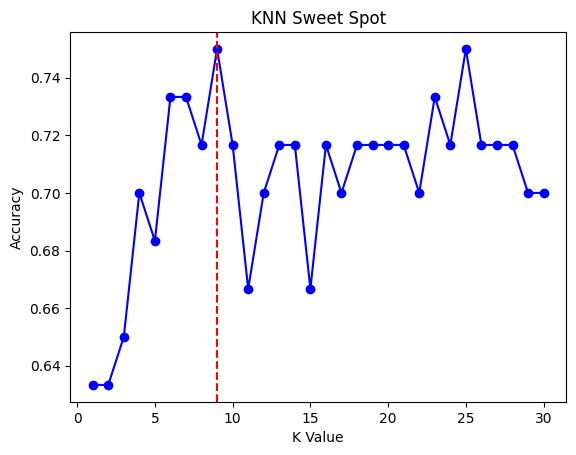

In [120]:
# Using Euidelian Distance

k_accuracies = []
k_values = list(range(1, 31))

for k in range(1,31):
    k_edu = KNNClassifierScratch(k=k)
    k_edu.fit(X_train_scaled, y_train)
    pred = k_edu.predict(X_test_scaled)
    accuracy = np.mean(pred == y_test)

    k_accuracies.append(accuracy)


best_k = k_values[np.argmax(k_accuracies)]
print(f"🎯 Sweet Spot K = {best_k} (Max Accuracy = {max(k_accuracies):.2%})")

# 3. Simple Plot
plt.plot(k_values, k_accuracies, marker='o', color='blue')
plt.axvline(x=best_k, color='red', linestyle='--') # Draws a simple red line on the best K
plt.title('KNN Sweet Spot')
plt.xlabel('K Value')
plt.ylabel('Accuracy')
plt.show()

🎯 Sweet Spot K = 25 (Max Accuracy = 76.67%)


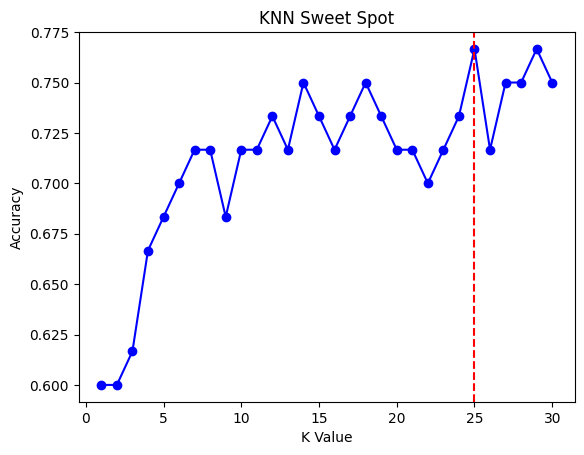

In [121]:
# Using Manhattan Distance

k_accuracies_m = []
k_values = list(range(1, 31))

for k in range(1,31):
    k_edu = KNNClassifierManhattan(k=k)
    k_edu.fit(X_train_scaled, y_train)
    pred = k_edu.predict(X_test_scaled)
    accuracy = np.mean(pred == y_test)

    k_accuracies_m.append(accuracy)

best_k = k_values[np.argmax(k_accuracies_m)]
print(f"🎯 Sweet Spot K = {best_k} (Max Accuracy = {max(k_accuracies_m):.2%})")

# 3. Simple Plot
plt.plot(k_values, k_accuracies_m, marker='o', color='blue')
plt.axvline(x=best_k, color='red', linestyle='--') # Draws a simple red line on the best K
plt.title('KNN Sweet Spot')
plt.xlabel('K Value')
plt.ylabel('Accuracy')
plt.show()

🎯 Sweet Spot K = 9 (Max Accuracy = 75.00%)


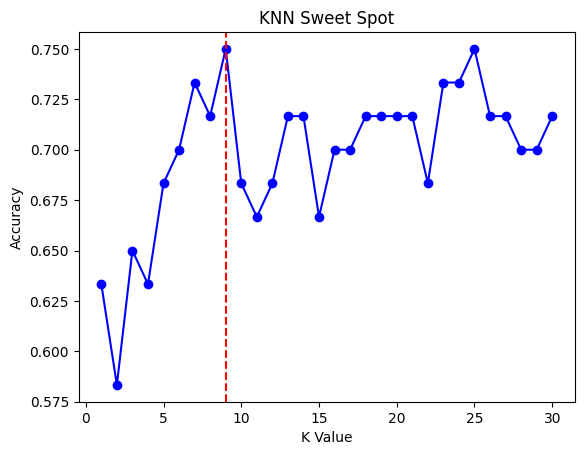

In [122]:
# Using Sklearn

from sklearn.neighbors import KNeighborsClassifier

model_results = []
k_values = list(range(1, 31))

for k in range(1,31):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)

    prediction = model.predict(X_test_scaled)
    probability = model.predict_proba(X_test_scaled)

    model_accuracy = model.score(X_test_scaled, y_test)

    model_results.append(model_accuracy)

best_k = k_values[np.argmax(model_results)]
print(f"🎯 Sweet Spot K = {best_k} (Max Accuracy = {max(model_results):.2%})")

# 3. Simple Plot
plt.plot(k_values, model_results, marker='o', color='blue')
plt.axvline(x=best_k, color='red', linestyle='--')
plt.title('KNN Sweet Spot')
plt.xlabel('K Value')
plt.ylabel('Accuracy')
plt.show()

🎯 Sweet Spot K = 25 (Max Accuracy = 76.67%)


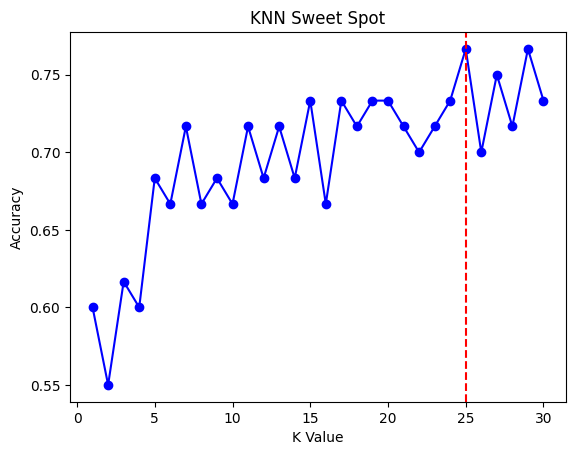

In [124]:
# Using Sklearn

from sklearn.neighbors import KNeighborsClassifier

model_results = []
k_values = list(range(1, 31))

for k in range(1,31):
    model = KNeighborsClassifier(n_neighbors=k, metric= 'manhattan')
    model.fit(X_train_scaled, y_train)

    prediction = model.predict(X_test_scaled)
    probability = model.predict_proba(X_test_scaled)

    model_accuracy = model.score(X_test_scaled, y_test)

    model_results.append(model_accuracy)

best_k = k_values[np.argmax(model_results)]
print(f"🎯 Sweet Spot K = {best_k} (Max Accuracy = {max(model_results):.2%})")

# 3. Simple Plot
plt.plot(k_values, model_results, marker='o', color='blue')
plt.axvline(x=best_k, color='red', linestyle='--')
plt.title('KNN Sweet Spot')
plt.xlabel('K Value')
plt.ylabel('Accuracy')
plt.show()